In [22]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_predict





plt.rcParams["font.family"] = "Malgun Gothic"  
plt.rcParams["axes.unicode_minus"] = False      

In [23]:
df = pd.read_csv("../data/dataset.csv")

df.head()

,url,brand_name,product_name,price_current,product_id,total_reviews,repurchase_reviews,repurchase_rate,ingredients_text
0,https://www.oliveyoung.co.kr/store/goods/getGoodsDetail.do?goodsNo=A000000222698&dispCatNo=1000001000100140001&trackingCd=Result_1,아누아,[수지세럼] 아누아 피디알엔 히알루론산 캡슐 100 세럼 30mL 기획 (+30mL 리필팩),27500,A000000222698,500,70,14.0,"하이드롤라이즈드하이알루로닉애씨드(29,049ppm), 나이아신아마이드, 하이드롤라이즈드콜라겐, 소듐하이알루로 네이트(800ppm), 아데노신, 소듐디엔에이(100ppm), 하이알 루로닉애씨드(30ppm), 하이드롤라이즈드소듐하이알루로네이 트(30ppm), 하이드록시프로필트라이모늄하이알루로네이트 (30ppm), 포타슘하이알루로네이트(30ppm), 소듐하이알루 로네이트크로스폴리머(30ppm), 소듐아세틸레이티드하이알 루로네이트(1ppm), 시트릭애씨드\n* 피디알엔: 소듐디엔에이"
1,https://www.oliveyoung.co.kr/store/goods/getGoodsDetail.do?goodsNo=A000000248826&dispCatNo=1000001000100150001&trackingCd=Result_2,메디큐브,[여배우광채크림] 메디큐브 PDRN 핑크 콜라겐 캡슐크림 55g 기획 (+4.5g*2ea),23800,A000000248826,500,20,4.0,"정제수, 글리세린, 나이아신아마이드, 메틸프로판다이올, 프로판다이올, 1,2-헥산다이올, 다이프로필렌글라이콜, 카프릴릭/카프릭트라이글리세라이드, 부틸렌글라이콜, 글리세레스-26, 알지닌, 카보머, 세테아릴알코올, 세테아릴올리베이트, 에틸헥실팔미테이트, 솔비탄올리베이트, 스쿠알란, 암모늄아크릴로일다이메틸타우레이트/브이피코폴리머, 시메티콘, 에틸헥실글리세린, 지치뿌리추출물, 아데노신, 해바라기씨오일, 폴리아크릴레이트-13, 소듐디엔에이(200ppm), 다이소듐이디티에이, 폴리아이소부텐, 글리세릴스테아레이트, 하이드롤라이즈드스클레로튬검, 서양배추출물, 알간나무커넬오일, 다마스크장미꽃수, 오리스뿌리추출물, 폴리솔베이트20, 멜론추출물, 솔비탄아이소스테아레이트, 서양송악잎/줄기추출물, 글루타티온, 소듐하이알루로네이트, 옥틸도데칸올, 연어알추출물, 하이드록시프로필트라이모늄하이알루로네이트, 토코페롤, 하이드로제네이티드레시틴, 세라마이드엔피, 사이아노코발아민, 티옥틱애씨드, 소듐아세틸레이티드하이알루로네이트, 하이드롤라이즈드콜라겐추출물(0.1ppm), 하이드롤라이즈드하이알루로닉애씨드, 아세틸헥사펩타이드-8, 카퍼트라이펩타이드-1, 카프릴릴글라이콜, 하이알루로닉애씨드, 팔미토일펜타펩타이드-4, 팔미토일헥사펩타이드-12, 소듐하이알루로네이트크로스폴리머, 하이드롤라이즈드소듐하이알루로네이트, 포타슘하이알루로네이트"
2,https://www.oliveyoung.co.kr/store/goods/getGoodsDetail.do?goodsNo=A000000226498&dispCatNo=1000001000100140001&trackingCd=Result_3,메디큐브,[1등미백앰플] 메디큐브 PDRN 핑크 앰플 30ml 기획 (본품+리필 50ML+겔패드 2매입*2개),24600,A000000226498,500,50,10.0,"정제수,글리세린,다이프로필렌글라이콜,아이소프로필미리스테이트,글리세레스-26,나이아신아마이드,1,2-헥산다이올,소듐디엔에이,부틸렌글라이콜,폴리글리세린-3,소듐아크릴레이트/소듐아크릴로일다이메틸타우레이트코폴리머,폴리아이소부텐,아크릴레이트/C10-30알킬아크릴레이트크로스폴리머,이리추출물,트로메타민,글리세릴아크릴레이트/아크릴릭애씨드코폴리머,피브이엠/엠에이코폴리머,에틸헥실글리세린,카프릴릴글라이콜,향료,인도멀구슬나무잎추출물,아데노신,카프릴릴/카프릴글루코사이드,솔비탄올리에이트,인도멀구슬나무꽃추출물,소듐하이알루로네이트,다이소듐이디티에이,울금뿌리추출물,사이아노코발아민,하이드롤라이즈드콜라겐,유비퀴논,홀리바질잎추출물,참산호말추출물,팔미토일펜타펩타이드-4,팔미토일트라이펩타이드-1,팔미토일테트라펩타이드-7,카퍼트라이펩타이드-1,아세틸헥사펩타이드-8,연어알추출물,아텔로콜라겐"
3,https://www.oliveyoung.co.kr/store/goods/getGoodsDetail.do?goodsNo=A000000243433&dispCatNo=1000001000100100001&trackingCd=Result_4,메디큐브,[청담샵 화잘먹미스트/시원촉촉] 메디큐브 PDRN 핑크 콜라겐 글로우 젤리 미스트 100ml 더블기획,29900,A000000243433,500,30,6.0,"콜라겐수(80.9%), 아이소프로필미리스테이트, 글리세린, 나이아신아마이드, 1,2-헥산다이올, 정제수, 소듐클로라이드, 메도우폼씨오일, 부틸렌글라이콜, 하이드록시아세토페논, 프로판다이올, 젤란검, 소듐디엔에이(1,081ppm), 해바라기씨오일, 에틸헥실글리세린, 아데노신, 트라이에틸시트레이트, 옥수수커넬추출물, 알칸나뿌리추출물, 다이소듐이디티에이, 토코페롤, 하이알루로닉애씨드, 하이드롤라이즈드하이알루로닉애씨드, 소듐하이알루로네이트, 콜라겐(10.8ppm), 프룩탄, 만주자작나무껍질/잎추출물, 피마자씨오일, 글루코오스, 레몬그라스잎오일, 스타아니스열매/씨오일, 스쿠알란, 글루타티온, 하이드롤라이즈드엘라스틴, 연어알추출물, 말토덱스트린, 카프릴릭/카프릭트라이글리세라이드, 하이드로제네이티드레시틴, 세라마이드엔피, 소듐시트레이트, 카프릴릴글라이콜, 소듐포스페이트, 시트릭애씨드, 진주추출물, 사이아노코발아민, 에스에이치-올리고펩타이드-1"
4,https://www.oliveyoung.co.kr/store/goods/getGoodsDetail.do?goodsNo=A000000231892&dispCatNo=1000001000100150001&trackingCd=Result_5,아누아,[수지pick/단독기획] 아누아 피디알엔 히알루론산 100 수분 크림 60mL 2입 기획,29500,A000000231892,500,120,24.0,"정제수, 스쿠알란, 글리세린, 나이아신아마이드, 펜틸렌글라이콜, 1,2-헥산다이올, 소듐디엔에이(1,000ppm), 하이드롤라이즈드콜라겐(1,000ppm), 소듐하이알루로네이트(600ppm), 인도멀구슬나무잎추출물, 하이드롤라이즈드하이알루로닉애씨드(300ppm), 인도멀구슬나무꽃추출물, 아이비고드열매추출물, 하이알루로닉애씨드(100ppm), 알로에베라꽃추출물, 가지열매추출물, 홀리바질잎추출물, 참산호말추출물, 울금뿌리추출물, 병풀잎추출물, 다이페닐실록시페닐트라이메티콘, 피씨에이다이메티콘, 부틸렌글라이콜, 프로판다이올, 암모늄아크릴로일다이메틸타우레이트/브이피코폴리머, 다이글리세린, 하이드록시에틸아크릴레이트/소듐아크릴로일다이메틸타우레이트코폴리머, 아크릴레이트/C10-30알킬아크릴레이트크로스폴리머, C12-20알킬글루코사이드, 메틸프로판다이올, 에틸헥실글리세린, 아데노신, 소듐파이테이트, 아미노메틸프로판다이올, 피브이엠/엠에이코폴리머, 마데카소사이드, C12-13알케스-9, 다이메틸실란올하이알루로네이트(750ppb), 하이드롤라이즈드소듐하이알루로네이트(750ppb), 아시아티코사이드, 포타슘하이알루로네이트(500ppb), 하이드록시프로필트라이모늄하이알루로네이트(400ppb), 소듐하이알루로네이트크로스폴리머(400ppb), 소듐하이알루로네이트다이메틸실란올(250ppb), 소듐아세틸레이티드하이알루로네이트(200ppb), 베헤닐알코올, C14-22알코올, 카보머"


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   url                 159 non-null    str    
 1   brand_name          159 non-null    str    
 2   product_name        159 non-null    str    
 3   price_current       159 non-null    int64  
 4   product_id          159 non-null    str    
 5   total_reviews       159 non-null    int64  
 6   repurchase_reviews  159 non-null    int64  
 7   repurchase_rate     159 non-null    float64
 8   ingredients_text    154 non-null    str    
dtypes: float64(1), int64(3), str(5)
memory usage: 11.3 KB


In [25]:
df.isna().sum()

url                   0
brand_name            0
product_name          0
price_current         0
product_id            0
total_reviews         0
repurchase_reviews    0
repurchase_rate       0
ingredients_text      5
dtype: int64

## 전처리 1: 품절 상품 제거 

In [26]:
df = df[df["brand_name"] != "일시품절"].copy()
df.reset_index(drop=True, inplace=True)

print("남은 상품 수:", len(df))

남은 상품 수: 140


## 전처리 2: ppm 추출

전성분 텍스트에서 정규표현식으로 소듐디엔에이(PDRN) 함량 수치를 추출한다.
단위(ppm/ppb/%)를 통일하여 ppm으로 환산한다.

In [27]:
def extract_pdrn_info(text):
    if pd.isna(text):
        return pd.Series([np.nan, np.nan])

    text = str(text)

    pattern = r"소듐디엔에이\s*\(\s*([0-9,.]+)\s*(ppm|ppb|%)\s*\)"

    match = re.search(pattern, text, flags=re.IGNORECASE)

    if not match:
        return pd.Series([np.nan, np.nan])

    raw_text = match.group(0)  # 원본 추출 결과
    value = float(match.group(1).replace(",", ""))
    unit = match.group(2).lower()

    if unit == "ppm":
        ppm = value

    elif unit == "ppb":
        ppm = value / 1000

    elif unit == "%":
        ppm = value * 10000

    else:
        ppm = np.nan

    return pd.Series([raw_text, ppm])

df[["pdrn_original_text", "pdrn_ppm"]] = df["ingredients_text"].apply(extract_pdrn_info)

print("PDRN 함량 추출 성공 개수:", df["pdrn_ppm"].notna().sum())

#display(
#   df[
#      ["product_name",
#         "pdrn_original_text",
#         "pdrn_ppm"]
#    ]
#    .dropna()
#)


PDRN 함량 추출 성공 개수: 59


In [28]:
print(df["pdrn_ppm"].describe())

count        59.000000
mean       3360.776805
std       13514.164060
min           0.000500
25%           1.500000
50%         100.100000
75%        1081.000000
max      100000.000000
Name: pdrn_ppm, dtype: float64


In [29]:
df["pdrn_ppm"].sort_values()

19     0.0005
42     0.0005
109    0.0005
95     0.0100
72     0.0200
        ...  
135       NaN
136       NaN
137       NaN
138       NaN
139       NaN
Name: pdrn_ppm, Length: 140, dtype: float64

## 전처리 3: 중복 제품 제거

동일 제품이 기획(증정품·용량 묶음)에 따라 중복으로 등록된 경우를 통합한다.

**name_core 추출 규칙**
- 제품명 앞의 마케팅 태그 (`[수지pick]`, `[NEW]` 등 대괄호 표현) 제거
- 기획·용량 표현 (`기획`, `더블기획`, `30mL`, `2입` 등) 제거

**그룹 집계 규칙**
- `repurchase_rate`: 그룹 내 **평균** (기획별 노이즈 제거)
- `price_current`: 그룹 내 **평균**
- `total_reviews`: 500인 행이 하나라도 있으면 **500**, 없으면 **최댓값** (올리브영 리뷰 수집 상한 500 반영)
- `pdrn_ppm`: 그룹 내 **첫 번째 non-null** (동일 제품은 전성분 동일 가정)

In [30]:
# 핵심 제품명 추출
df['name_core'] = (
    df['product_name']
    .str.replace(r'^\[.*?\]\s*', '', regex=True)
    .str.replace(r'\s*(기획|더블기획|기획세트|단독기획|2입.*|듀오.*|\d+mL.*|\d+ml.*|\d+g.*)', '', regex=True)
    .str.strip()
)

# 중복 그룹 집계
def agg_group(grp):
    reviews = grp['total_reviews']
    total_reviews_val = 500 if (reviews == 500).any() else reviews.max()

    ppm_vals = grp['pdrn_ppm'].dropna().unique()
    if len(ppm_vals) > 1:
        print(f"ppm 불일치 [{grp.name}]: {ppm_vals} → 첫 번째 값 사용")
    pdrn_ppm_val = ppm_vals[0] if len(ppm_vals) > 0 else np.nan

    return pd.Series({
        'brand_name'     : grp['brand_name'].iloc[0],
        'product_name'   : grp['product_name'].iloc[0], 
        'price_current'  : grp['price_current'].mean().round(0),
        'repurchase_rate': grp['repurchase_rate'].mean().round(2),
        'total_reviews'  : total_reviews_val,
        'pdrn_ppm'       : pdrn_ppm_val,
        'ppm_disclosed'  : 1 if len(ppm_vals) > 0 else 0,
    })

df_clean = df.groupby('name_core').apply(agg_group).reset_index()

print(f"중복 제거 전: {len(df)}개")
print(f"중복 제거 후: {len(df_clean)}개  (-{len(df)-len(df_clean)}개)")

#pd.set_option('display.max_rows', None)
#pd.set_option('display.max_colwidth', None)

#display(
#    df_clean[['brand_name', 'name_core', 'product_name', 'pdrn_ppm', 'price_current', 'repurchase_rate']]
#    .sort_values(['brand_name', 'name_core'])
#    .reset_index(drop=True)
#)


중복 제거 전: 140개
중복 제거 후: 121개  (-19개)


## 전처리 4: 수동 중복 제거

자동 추출된 `name_core`가 다르더라도 실질적으로 동일 제품으로 판단되는 경우를 수동으로 통합한다.

**통합 기준**
- 용량만 다른 경우 
- 색상·호수만 다른 경우 
- 띄어쓰기·PDRN 표기 방식만 다른 경우 
- 세트·단품 구성만 다른 경우

**집계 규칙은 전처리 3과 동일**
- `repurchase_rate`: 그룹 내 평균
- `price_current`: 그룹 내 평균  
- `total_reviews`: 500인 행이 하나라도 있으면 500, 없으면 최댓값
- `pdrn_ppm`: 그룹 내 첫 번째 non-null

**추가 보완**
- 더마팩토리 PDRN 4% 앰플: 전성분표 미기재이나 제품명에 함량(4%) 명시 → 40,000ppm 수동 입력

In [31]:
df_clean = df_clean.sort_values(['brand_name', 'name_core']).reset_index(drop=True)


manual_groups = [
    [1, 3],
    [12, 13],
    [42, 43],
    [46, 47],
    [55, 56],
    [59, 60],
    [79, 80],
    [93, 94, 95],
    [96, 97],
    [100, 101],
    [115, 118, 119],
    [114, 117],
]

for group in manual_groups:
    representative_name = df_clean.iloc[group[0]]['name_core']
    df_clean.loc[group, 'name_core'] = representative_name

#같은 방식으로 재집계
df_clean = df_clean.groupby('name_core').agg(
    brand_name      = ('brand_name', 'first'),
    product_name    = ('product_name', 'first'),
    price_current   = ('price_current', 'mean'),
    repurchase_rate = ('repurchase_rate', 'mean'),
    total_reviews   = ('total_reviews', lambda x: 500 if (x == 500).any() else x.max()),
    pdrn_ppm        = ('pdrn_ppm', lambda x: x.dropna().iloc[0] if x.notna().any() else np.nan),
    ppm_disclosed   = ('ppm_disclosed', 'max'),
).reset_index()

df_clean['price_current']   = df_clean['price_current'].round(0)
df_clean['repurchase_rate'] = df_clean['repurchase_rate'].round(2)

#추가) ppm 수치 수동 입력   
mask = df_clean['name_core'] == '더마팩토리 PDRN 4% 앰플'
df_clean.loc[mask, 'pdrn_ppm'] = 40000.0
df_clean.loc[mask, 'ppm_disclosed'] = 1

print(f"수동 중복 제거 후: {len(df_clean)}개")

#df_clean

수동 중복 제거 후: 107개


## H1. PDRN ppm 수치를 공개한 제품은 미공개 제품에 비해 평균 가격과 재구매율이 모두 유의미하게 높을 것이다.

본 가설에서는 PDRN ppm 수치를 공개한 제품과 공개하지 않은 제품 사이에 가격 및 재구매율 차이가 존재하는지 확인한다.  
ppm 공개 여부는 소비자가 제품의 성분 함량 정보를 직접 확인할 수 있는지와 관련된 정보 투명성 변수로 해석할 수 있다.

유의수준은 0.05로 설정하였다. 이는 사회과학 및 소비자 행동 연구에서 가장 널리 사용되는 기준으로, 귀무가설이 참일 때 이를 잘못 기각할 확률을 5% 이하로 통제함을 의미한다. 본 연구는 표본 크기가 107개로 크지 않고 가격/재구매율 분포의 정규성이 보장되지 않는 점을 고려하여, Welch t-test와 함께 분포 가정에 자유로운 비모수 검정인 Mann-Whitney U test를 병행 실시하였다.

In [32]:
from scipy import stats

disclosed   = df_clean[df_clean['ppm_disclosed'] == 1]
undisclosed = df_clean[df_clean['ppm_disclosed'] == 0]

print(f"ppm 공개 제품: {len(disclosed)}개 / 미공개 제품: {len(undisclosed)}개\n")

for var, label in [('price_current', '가격'), ('repurchase_rate', '재구매율')]:
    print(f"[{label}]")
    print(f"  공개   mean={disclosed[var].mean():.2f}  median={disclosed[var].median():.2f}  std={disclosed[var].std():.2f}")
    print(f"  미공개 mean={undisclosed[var].mean():.2f}  median={undisclosed[var].median():.2f}  std={undisclosed[var].std():.2f}")

    #Welch t-test
    t_stat, t_p = stats.ttest_ind(disclosed[var], undisclosed[var], equal_var=False)
    #Mann-Whitney U
    u_stat, u_p = stats.mannwhitneyu(disclosed[var], undisclosed[var], alternative='two-sided')

    print(f"  Welch t-test  → t={t_stat:.3f}, p={t_p:.4f}  {'*유의*' if t_p < 0.05 else '비유의'}")
    print(f"  Mann-Whitney  → U={u_stat:.1f},  p={u_p:.4f}  {'*유의*' if u_p < 0.05 else '비유의'}\n")

ppm 공개 제품: 46개 / 미공개 제품: 61개

[가격]
  공개   mean=27749.37  median=25450.00  std=11339.22
  미공개 mean=30448.31  median=27000.00  std=13118.65
  Welch t-test  → t=-1.139, p=0.2574  비유의
  Mann-Whitney  → U=1231.0,  p=0.2805  비유의

[재구매율]
  공개   mean=6.78  median=4.00  std=7.45
  미공개 mean=10.70  median=5.00  std=15.97
  Welch t-test  → t=-1.689, p=0.0947  비유의
  Mann-Whitney  → U=1309.0,  p=0.5501  비유의



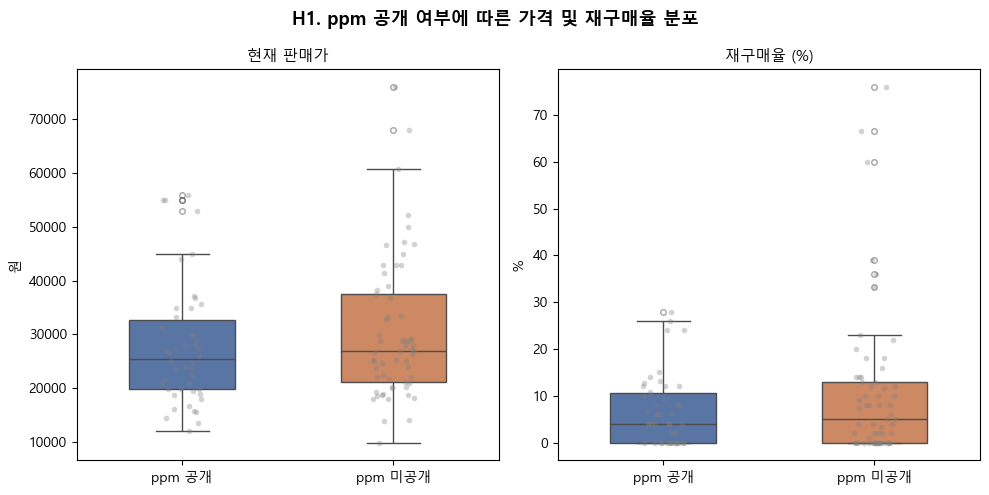

In [33]:
#시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("H1. ppm 공개 여부에 따른 가격 및 재구매율 분포", fontsize=13, fontweight='bold')

plot_df = df_clean.copy()
plot_df['ppm_공개여부'] = plot_df['ppm_disclosed'].map({1: 'ppm 공개', 0: 'ppm 미공개'})

for ax, (col, title, unit) in zip(axes, [
    ('price_current',   '현재 판매가',  '원'),
    ('repurchase_rate', '재구매율 (%)', '%'),
]):
    sns.boxplot(
    data=plot_df, x='ppm_공개여부', y=col, hue='ppm_공개여부', legend=False,
    palette={'ppm 공개': '#4C72B0', 'ppm 미공개': '#DD8452'},
    width=0.5, flierprops=dict(marker='o', markersize=4, alpha=0.5),
    ax=ax
)
    sns.stripplot(
        data=plot_df, x='ppm_공개여부', y=col,
        color='gray', alpha=0.35, size=4, jitter=True, ax=ax
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel(unit)

plt.tight_layout()
plt.show()

## H2. ppm 공개 제품군 내에서 재구매율을 예측할 때, PDRN 함량은 가격 정보보다 더 높은 중요도를 가질 것이다.

H2에서는 ppm 수치를 명시적으로 공개한 제품만을 대상으로, 실제 PDRN ppm 수치와 가격이 수집 리뷰 내 재구매율을 얼마나 설명할 수 있는지 분석한다.

분석 방법으로 Random Forest Regression을 사용하였다. 이는 비선형 관계를 반영할 수 있으며, 변수 중요도를 통해 가격과 PDRN 함량 중 어떤 변수가 재구매율 예측에 더 크게 기여했는지 확인할 수 있다.

본 분석에서 `total_reviews`는 실제 전체 리뷰 수가 아니라 최대 500개로 제한된 수집 결과이므로 독립변수에서 제외하였다.

In [34]:
df_h2 = disclosed[['pdrn_ppm', 'price_current', 'repurchase_rate']].dropna().copy()

print(f"H2 분석 대상 제품 수: {len(df_h2)}개")

X = df_h2[['pdrn_ppm', 'price_current']]
y = df_h2['repurchase_rate']

rf = RandomForestRegressor(n_estimators=500, random_state=42)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_r2  = cross_val_score(rf, X, y, cv=kf, scoring='r2')
cv_mae = cross_val_score(rf, X, y, cv=kf, scoring='neg_mean_absolute_error')

print(f"\n[5-Fold Cross Validation 결과]")
print(f"  R²  평균: {cv_r2.mean():.4f}  (std: {cv_r2.std():.4f})")
print(f"  MAE 평균: {(-cv_mae).mean():.4f}  (std: {(-cv_mae).std():.4f})")

#변수 중요도 확인
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(f"\n[변수 중요도]")
for feat, imp in importances.items():
    print(f"  {feat}: {imp:.4f}")

H2 분석 대상 제품 수: 46개

[5-Fold Cross Validation 결과]
  R²  평균: 0.2782  (std: 0.1476)
  MAE 평균: 4.6530  (std: 1.4893)

[변수 중요도]
  price_current: 0.6574
  pdrn_ppm: 0.3426


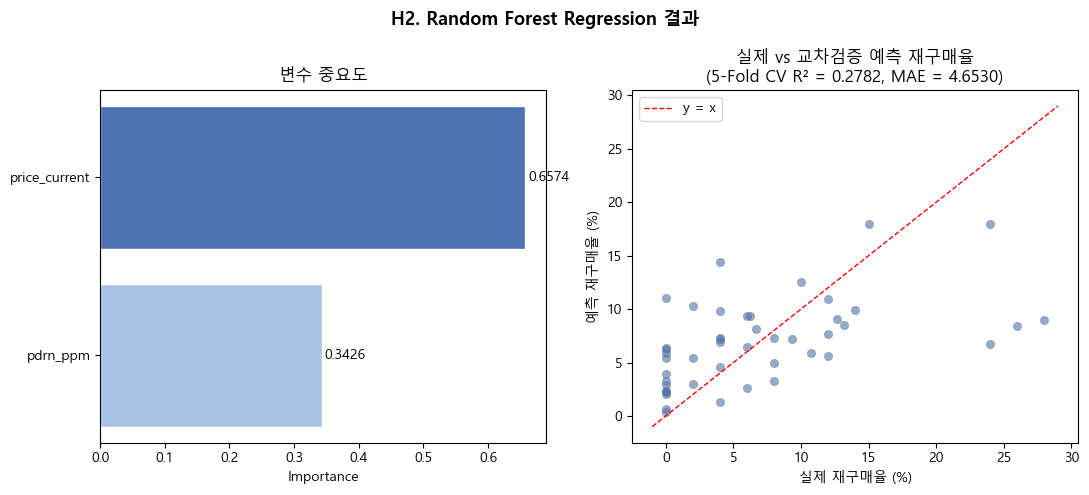

In [35]:
y_pred_cv = cross_val_predict(rf, X, y, cv=kf)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("H2. Random Forest Regression 결과", fontsize=13, fontweight='bold')

#변수 중요도
colors = ['#4C72B0' if imp == importances.max() else '#A9C4E2' for imp in importances]
axes[0].barh(importances.index, importances.values, color=colors, edgecolor='white')
axes[0].set_title("변수 중요도")
axes[0].set_xlabel("Importance")
axes[0].invert_yaxis()

for i, v in enumerate(importances.values):
    axes[0].text(v + 0.005, i, f"{v:.4f}", va='center', fontsize=10)

axes[1].scatter(
    y, y_pred_cv,
    alpha=0.6,
    edgecolors='gray',
    linewidths=0.5,
    color='#4C72B0'
)

lims = [min(y.min(), y_pred_cv.min()) - 1, max(y.max(), y_pred_cv.max()) + 1]
axes[1].plot(lims, lims, 'r--', linewidth=1, label='y = x')

axes[1].set_title(
    f"실제 vs 교차검증 예측 재구매율\n"
    f"(5-Fold CV R² = {cv_r2.mean():.4f}, MAE = {(-cv_mae).mean():.4f})"
)
axes[1].set_xlabel("실제 재구매율 (%)")
axes[1].set_ylabel("예측 재구매율 (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

## H3. ppm 공개 제품군을 군집화했을 때, 높은 가격과 낮은 재구매율 특성을 보이는 군집이 독립적으로 존재할 것이다.

H3에서는 ppm 수치를 공개한 제품군을 대상으로 가격, 실제 PDRN ppm 수치, 수집 리뷰 내 재구매율을 기준으로 제품군을 군집화한다.

이 분석의 목적은 PDRN 제품이 실제 함량과 소비자 반응 기준으로 어떤 시장 유형으로 나뉘는지 확인하는 것이다. 특히 실제 ppm 수치가 높은 제품이 높은 재구매율을 보이는지, 혹은 고가격임에도 ppm 수치와 재구매율이 낮은 제품군이 존재하는지를 확인한다.

K-means 군집화에는 `price_current`, `pdrn_ppm`, `repurchase_rate` 세 변수를 사용하였다. 변수 간 단위 차이가 크기 때문에 StandardScaler를 이용해 표준화한 뒤 군집분석을 수행하였다.

In [36]:
df_h3 = disclosed[[
    'pdrn_ppm',
    'price_current',
    'repurchase_rate'
]].dropna().copy()

df_h3 = df_h3.reset_index(drop=False)

print("H3 분석 대상 제품 수:", len(df_h3))

display(df_h3.head())

H3 분석 대상 제품 수: 46


,index,pdrn_ppm,price_current,repurchase_rate
0,0,0.5000,45000.0,24.00
1,3,0.0005,26867.0,9.33
2,4,3.4500,23500.0,4.00
3,5,0.5000,35600.0,14.00
4,6,0.5000,36800.0,4.00


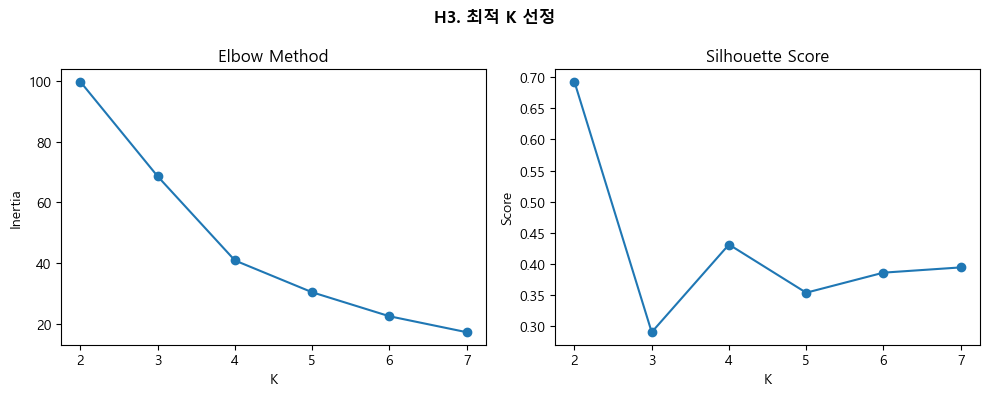


Silhouette score:
  K=2: 0.6926
  K=3: 0.2901
  K=4: 0.4311
  K=5: 0.3536
  K=6: 0.3859
  K=7: 0.3943


In [37]:
#최적 k 선정
cluster_features = [
    'price_current',
    'pdrn_ppm',
    'repurchase_rate'
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_h3[cluster_features])

inertias = []
sil_scores = []

K_range = range(2, 8)

for k in K_range:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = km.fit_predict(X_scaled)
    
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle("H3. 최적 K 선정", fontsize=12, fontweight='bold')

axes[0].plot(K_range, inertias, 'o-')
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")

axes[1].plot(K_range, sil_scores, 'o-')
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

print("\nSilhouette score:")
for k, s in zip(K_range, sil_scores):
    print(f"  K={k}: {s:.4f}")

In [38]:
#k-means (k=4로 선정)
BEST_K = 4

km_final = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=20
)

df_h3['cluster'] = km_final.fit_predict(X_scaled)

cluster_summary = df_h3.groupby('cluster').agg(
    n=('cluster', 'size'),
    avg_price=('price_current', 'mean'),
    avg_pdrn_ppm=('pdrn_ppm', 'mean'),
    avg_repurchase_rate=('repurchase_rate', 'mean')
).round(2)

display(cluster_summary)

,n,avg_price,avg_pdrn_ppm,avg_repurchase_rate
cluster,,,,
0,32,23861.06,3383.48,4.72
1,8,29264.62,512.88,19.61
2,5,52620.00,2800.00,0.80
3,1,15700.00,100000.00,0.00


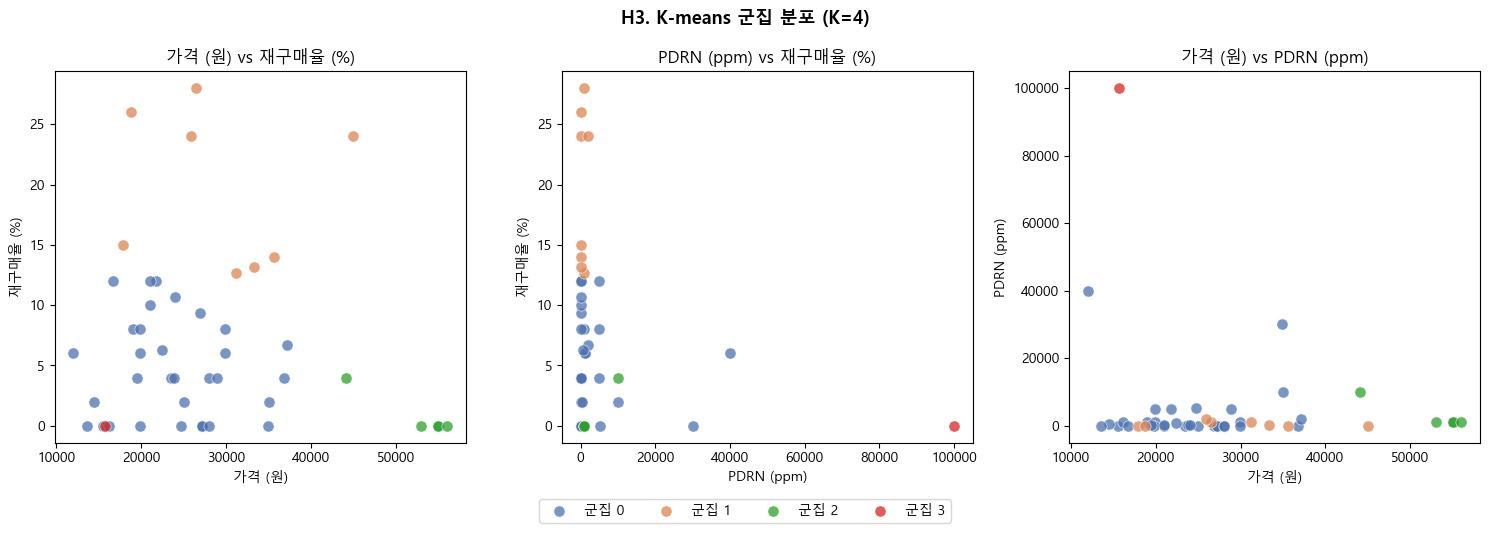

In [39]:
#시각화
palette = ['#4C72B0', '#DD8452', '#2CA02C', '#D62728']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("H3. K-means 군집 분포 (K=4)", fontsize=13, fontweight='bold')

plot_pairs = [
    ('price_current', 'repurchase_rate', '가격 (원)', '재구매율 (%)'),
    ('pdrn_ppm', 'repurchase_rate', 'PDRN (ppm)', '재구매율 (%)'),
    ('price_current', 'pdrn_ppm', '가격 (원)', 'PDRN (ppm)')
]

for ax, (xcol, ycol, xlabel, ylabel) in zip(axes, plot_pairs):
    for c in sorted(df_h3['cluster'].unique()):
        grp = df_h3[df_h3['cluster'] == c]
        ax.scatter(
            grp[xcol],
            grp[ycol],
            label=f'군집 {c}',
            color=palette[c],
            alpha=0.75,
            edgecolors='white',
            linewidths=0.5,
            s=65
        )
        
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{xlabel} vs {ylabel}")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    ncol=4,
    bbox_to_anchor=(0.5, -0.06)
)

plt.tight_layout()
plt.show()

In [40]:
result = (
    df_h3
    .merge(
        df_clean[['brand_name', 'name_core']],
        left_on='index',
        right_index=True,
        how='left'
    )
    [[
        'cluster',
        'brand_name',
        'name_core',
        'price_current',
        'pdrn_ppm',
        'repurchase_rate'
    ]]
    .sort_values(['cluster', 'price_current'], ascending=[True, False])
    .reset_index(drop=True)
)

pd.set_option('display.max_colwidth', None)

for c in sorted(result['cluster'].unique()):
    grp = result[result['cluster'] == c]
    
    print(
        f"\n── 군집 {c}  "
        f"(n={len(grp)}, "
        f"avg price={grp['price_current'].mean():.0f}원, "
        f"avg ppm={grp['pdrn_ppm'].mean():.1f}, "
        f"avg 재구매율={grp['repurchase_rate'].mean():.2f}%)"
    )
    
    display(grp.drop(columns='cluster').head(10))


── 군집 0  (n=32, avg price=23861원, avg ppm=3383.5, avg 재구매율=4.72%)


,brand_name,name_core,price_current,pdrn_ppm,repurchase_rate
0,아누아,아누아 피디알엔 히알루론산 수분 캡슐 미스트,37167.0,2000.0,6.67
1,VT,VT 피디알엔 캡슐 크림 100,36800.0,0.5,4.00
2,더마라인,더마라인 디렉소 PDRN 솔루션 살몬 앰플,35000.0,10000.0,2.00
3,오아조,오아조 피디알엔 쓰리디 부스팅 앰플,34900.0,30000.0,0.00
4,메디큐브,메디큐브 PDRN 핑크 콜라겐 글로우 젤리 미스트,29900.0,1081.0,6.00
5,이지듀,이지듀 스킨부스터 샷 앰플 4종 (,29900.0,18.0,8.00
6,제나벨,제나벨 PDRN 인리치드 리커버리 밤,28900.0,5000.0,4.00
7,샤이샤이샤이,샤이샤이샤이 알로에 PDRN 쿨링 리페어 앰플,28000.0,2.0,4.00
8,플리프,플리프 PDRN 포어엑스 올인원 로션,28000.0,5.0,0.00
9,런드리유,런드리유 PDRN 고체미스트,27200.0,1.0,0.00



── 군집 1  (n=8, avg price=29265원, avg ppm=512.9, avg 재구매율=19.61%)


,brand_name,name_core,price_current,pdrn_ppm,repurchase_rate
32,VT,VT PDRN 에센스,45000.0,0.5,24.00
33,VT,VT 피디알엔 에센스 100,35600.0,0.5,14.00
34,아누아,아누아 피디알엔 히알루론산 캡슐 100 세럼,33300.0,100.0,13.20
35,아누아,아누아 피디알엔 히알루론산 100 수분 크림,31167.0,1000.0,12.67
36,메디큐브,메디큐브 PDRN 핑크 시카 수딩 토너,26500.0,1000.0,28.00
37,센텔리안24,센텔리안24 마데카 크림 PDRN세트,25900.0,2000.0,24.00
38,메디힐,메디힐 PDRN 모공 탄력 세럼,18750.0,1.0,26.00
39,메디힐,메디힐 PDRN 모공 탄력 더마 크림,17900.0,1.0,15.00



── 군집 2  (n=5, avg price=52620원, avg ppm=2800.0, avg 재구매율=0.80%)


,brand_name,name_core,price_current,pdrn_ppm,repurchase_rate
40,플로위,플로위 PDRN 액티브 베리어 크림,56000.0,1000.0,0.0
41,더마라인,더마라인 디렉소 PDRN 솔루션 액티빙 에멀전,55000.0,1000.0,0.0
42,더마라인,더마라인 디렉소 PDRN 솔루션 액티빙 토너,55000.0,1000.0,0.0
43,플로위,플로위 PDRN 트리플 코어 앰플,53000.0,1000.0,0.0
44,더마라인,더마라인 디렉소 바이오 액티빙 PDRN 크림,44100.0,10000.0,4.0



── 군집 3  (n=1, avg price=15700원, avg ppm=100000.0, avg 재구매율=0.00%)


,brand_name,name_core,price_current,pdrn_ppm,repurchase_rate
45,나노레시피,"나노레시피 연어 PDRN 100,000ppm 앰플",15700.0,100000.0,0.0
